# FSPO Banking Decisions

## Imports

In [1]:
import json
import math
import re
import time
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path

from urllib.parse import urlencode, urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from matplotlib.patches import Patch
from requests.adapters import HTTPAdapter

from urllib3.util.retry import Retry

%matplotlib inline
pd.set_option("display.max_columns", 30)

pd.set_option("display.width", 160)

USE_CACHE = True        
CROSS_CHECK = True      
DELAY_SECONDS = 1.5    
TIMEOUT_SECONDS = 30
SECTOR = "1"            

pat  = Path.cwd()
RAW_DIR   = pat / "data" / "raw"
PROCESSED_DIR  = pat / "data" / "processed"
CACHE_DIR   = RAW_DIR / "html_cache"
CHART_DIR   = pat / "charts"

for d in (RAW_DIR, PROCESSED_DIR, CHART_DIR):
    d.mkdir(parents=True, exist_ok=True)

RAW_CSV = RAW_DIR / "fspo_banking_decisions.csv"

VERIFY_JSON = RAW_DIR / "scrape_verification.json"

CLEAN_CSV = PROCESSED_DIR / "fspo_banking_cleaned.csv"

QUALITY_JSON = PROCESSED_DIR / "data_quality_report.json"

STATS_JSON =   pat / "eda_statistics.json"

# Getting our data

In [2]:
src_link= "https://www.fspo.ie/complaint-outcomes/investigation-services/legally-binding-decisions/"

LISTING_URL   = urljoin(src_link, "display.asp")
FILTER_URL  = urljoin(src_link, "query.asp")

# we have the exact paramaters
PARAMS = {"dyear": "0", "product": "0", "conduct": "0", "sector": SECTOR,
          "outcome": "0", "decisionref": ""}

USER_AGENT = "Mozilla/5.0 (compatible; FSPO-EDA-academic/1.0; NCI student project; metadata only)"

COLUMNS = ["decision_reference", "decision_title", "financial_sector", "product_service",
           "primary_conduct", "outcome", "all_conducts", "decision_year", "decision_pdf_url",
           "source_page", "source_url", "scraped_at_utc"]


@dataclass
class ListingPage:
    
    page: int
    url: str
    
    reported_total: int | None
    last_updated_note: str | None
    max_page_link: int | None
    
    records: list   = field(default_factory=list)


def make_session(retries=4, backoff=2.0):
    
    session =   requests.Session()
    retry =  Retry(total=retries, connect=retries, read=retries, status=retries,
                   backoff_factor=backoff, status_forcelist=(429, 500, 502, 503, 504),
                   allowed_methods=frozenset({"GET"}), respect_retry_after_header=True)
    adapter =  HTTPAdapter(max_retries=retry)
    session.mount("https://", adapter)
    session.mount("http://", adapter)
    
    session.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "en-IE,en;q=0.8"})
    return session


def fetch(session, url, params=None):
    
    response  = session.get(url, params=  params, timeout  =TIMEOUT_SECONDS)
    response.raise_for_status()
    response.encoding = response.encoding or "utf-8"
    return response.text


def clean_text(value):
    
    if value is None:
        
        return None
    value =   re.sub(r"\s+", " ", value.replace("\xa0", " ")).strip()
    return value or None


def labelled_value(block, label):
    

    for span in block.find_all("span"):
        
        if clean_text(span.get_text())  == f"{label}:":
            
            text = span.parent.get_text(" ").replace(span.get_text(), "", 1)
            return clean_text(text)
            
    return None


def parse_decision_block(block):
    h3  = block.find("h3")
    title  = reference =    None
    
    if h3 is not None:
        ref_span =  h3.find("span")
        if ref_span is not None:
            
            m  = re.search(r"Decision Reference\s*(.+)", ref_span.get_text(" "), re.I)
            reference = clean_text(m.group(1)) if m else clean_text(ref_span.get_text())
        h3_link  = h3.find("a")
        if h3_link is not None:
            full =  h3_link.get_text(" ")
            if ref_span is not None:

                
                full  = full.replace(ref_span.get_text(" "), "")
            title   = clean_text(full)

            

    pdf_url =    None
    link = block.find("a", class_="button") or (h3.find("a") if h3 is not None else None)
    if link is not None and link.get("href"):
        
        pdf_url =  urljoin(src_link, link["href"].strip())

    return {
        "decision_reference": reference,
        
        "decision_title": title,
        
        "financial_sector":  labelled_value(block, "Sector"),
        
        "product_service":  labelled_value(block, "Product/Service"),
        
        "primary_conduct":  labelled_value(block, "Primary Conduct Complained Of"),
        
        "outcome": labelled_value(block, "Outcome"),

        "all_conducts": labelled_value(block, "All Conducts Complained Of"),
        
        "decision_year": labelled_value(block, "Year"),
        
        "decision_pdf_url":  pdf_url,
    }


def parse_listing(html, page, url):
    
    soup =  BeautifulSoup(html, "html.parser")
    reported_total = None
    nb = soup.find(class_="nbrecords")
    
    if nb is not None:
        m =  re.search(r"There are\s+([\d,]+)\s+decisions", nb.get_text(" "))
        if m:
            reported_total = int(m.group(1).replace(",", ""))

    note =  None
    m =  re.search(r"Last updated on[^<]{0,200}", html)
    if m:
        
        note  = clean_text(BeautifulSoup(m.group(0), "html.parser").get_text())

    page_numbers = [int(n) for n in re.findall(r"mypage=(\d+)", html)]
    pager = soup.find("p", attrs={"aria-label": "paging system"})
    if pager is not None and pager.find("i") is not None and pager.find("i").get_text(strip=True).isdigit():
        page_numbers.append(int(pager.find("i").get_text(strip=True)))
    max_page_link = max(page_numbers) if page_numbers else None

    records =    []
    for block in soup.select("div.decision"):
        
        rec = parse_decision_block(block)
        
        rec["source_page"] = page
        rec["source_url"] = url
        
        records.append(rec)
    return ListingPage(page, url, reported_total, note, max_page_link, records)


def listing_url(params, page):
    
    return f"{LISTING_URL}?{urlencode({**params, 'mypage': page})}"


def get_page(session, params, page):
    
    url  = listing_url(params, page)
    key   = "_".join(f"{k}-{v}" for k, v in params.items() if v not in ("", None))
    Cahce_fil  = CACHE_DIR / f"{key}_page{page:03d}.html"
    if USE_CACHE and Cahce_fil.exists():
        
        html  = Cahce_fil.read_text(encoding="utf-8")

    
    else:

        
        time.sleep(DELAY_SECONDS)
        html = fetch(session, url)
        Cahce_fil.parent.mkdir(parents=True, exist_ok=True)
        Cahce_fil.write_text(html, encoding="utf-8")
        
    return parse_listing(html, page, url)


## Scraping each page

In [3]:

session = make_session()

scraped_at =  datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")



FirsT  = get_page(session, PARAMS, 1)

if FirsT.reported_total is None or not FirsT.records:
    
    raise RuntimeError("Page 1 has no total or no decisions; the site layout may have changed.")
    
per_page = len(FirsT.records)
expected_pages = math.ceil(FirsT.reported_total / per_page)
print(f"Site says: {FirsT.reported_total:,} decisions | {per_page} per page | {expected_pages} pages")

print(f"Site note: {FirsT.last_updated_note}")

pages, page_errors = [FirsT], {}

for page in range(2, expected_pages + 1):
    try:
        
        lp = get_page(session, PARAMS, page)
        pages.append(lp)
        
    except requests.RequestException as exc:
        
        page_errors[page]  = repr(exc)
        print(f"  page {page}:  FAILED ({exc})")
    if page % 10 == 0 or page ==  expected_pages:
        
        print(f"  read up to page {page} ({sum(len(p.records) for p in pages):,} records so far)")

probe = get_page(session, PARAMS, expected_pages + 1)

seen = {r["decision_reference"] for p in pages for r in p.records}

probe_new = sum(1 for r in probe.records if r["decision_reference"] not in seen)

print(f"Probe page {expected_pages + 1}: {len(probe.records)} blocks, {probe_new} new references")



raw  = pd.DataFrame([r for p in pages for r in p.records])

raw["scraped_at_utc"] = scraped_at
raw_rows  = len(raw)

dups =  raw.loc[raw.duplicated("decision_reference"), "decision_reference"].tolist()

raw =  raw.drop_duplicates("decision_reference").reset_index(drop=True)[COLUMNS]

verification = {
    "scraped_at_utc": scraped_at,
    
    "last_updated_note": FirsT.last_updated_note,
    
    "reported_total": FirsT.reported_total,
    
    "records_per_page": per_page,
    
    "FirsT_page": 1,
    
    "last_page": expected_pages,
    
    "highest_page_number_linked": max(p.max_page_link or 0 for p in pages),
    
    "records_on_last_page": len(pages[-1].records),
    
    "page_errors": page_errors,
    
    "probe_page_unseen_records": probe_new,
    
    "raw_rows": raw_rows,
    
    "duplicate_references_removed": dups,
    
    "unique_decisions": int(raw["decision_reference"].nunique()),
}
verification["matches_reported_total"] = verification["unique_decisions"] ==  FirsT.reported_total

raw.to_csv(RAW_CSV, index=False, encoding="utf-8")

print(f"\nSaved {len(raw):,} decisions to {RAW_CSV}")
print("Matches the site total:", verification["matches_reported_total"])
raw.head()

Site says: 1,686 decisions | 25 per page | 68 pages
Site note: Last updated on 21 May 2026 with legally binding decisions up to the end of of March 2026.
  read up to page 10 (250 records so far)
  read up to page 20 (500 records so far)
  read up to page 30 (750 records so far)
  read up to page 40 (1,000 records so far)
  read up to page 50 (1,250 records so far)
  read up to page 60 (1,500 records so far)
  read up to page 68 (1,686 records so far)
Probe page 69: 0 blocks, 0 new references

Saved 1,686 decisions to C:\Users\Aditya\data\raw\fspo_banking_decisions.csv
Matches the site total: True


,decision_reference,decision_title,financial_sector,product_service,primary_conduct,outcome,all_conducts,decision_year,decision_pdf_url,source_page,source_url,scraped_at_utc
0,2018-0002,Credit Cards,Banking,Consumer Credit,Arrears handling,Substantially upheld,"Arrears handling , Delayed or inadequate commu...",2018,https://fspo.ie/complaint-outcomes/investigati...,1,https://www.fspo.ie/complaint-outcomes/investi...,2026-11-01T10:56:43Z
1,2018-0004,Personal Loan,Banking,Consumer Credit,Maladministration,Partially upheld,Maladministration,2018,https://fspo.ie/complaint-outcomes/investigati...,1,https://www.fspo.ie/complaint-outcomes/investi...,2026-11-01T10:56:43Z
2,2018-0011,Overdrafts,Banking,Commercial Banking,Customer Service,Partially upheld,"Delayed or inadequate communication, Maladmini...",2018,https://fspo.ie/complaint-outcomes/investigati...,1,https://www.fspo.ie/complaint-outcomes/investi...,2026-11-01T10:56:43Z
3,2018-0012,Repayment Mortgage,Banking,Mortgage,Refusal to give product/service,Partially upheld,"Refusal to grant mortgage, Arrears handling - ...",2018,https://fspo.ie/complaint-outcomes/investigati...,1,https://www.fspo.ie/complaint-outcomes/investi...,2026-11-01T10:56:43Z
4,2018-0013,Personal Loan,Banking,Consumer Credit,Mis-selling,Rejected,"Mis-selling, Complaint handling (Consumer Prot...",2018,https://fspo.ie/complaint-outcomes/investigati...,1,https://www.fspo.ie/complaint-outcomes/investi...,2026-11-01T10:56:43Z


## Comparing to the websites own filters

The site can be filtered by outcome, product and year and total is provided for each filter. If we have an equal number of scrapped counts to each of those totals, then the extract is complete and all the fields were read properly. On the one page with very few result sets the site does not display the count, tpatfore we count the decision blocks on this one page.

In [4]:
def filter_options(session, data):
    
    qp  =  {"data": data, "y": "", "s": PARAMS["sector"], "p": "", "c": "", "o": ""}
    soup  =   BeautifulSoup(fetch(session, FILTER_URL, params=qp), "html.parser")
    
    return {o.get("value"): clean_text(o.get_text()) for o in soup.find_all("option") if o.get("value")}


def site_total_for(session, params):
    
    
    page =   parse_listing(fetch(session, LISTING_URL, params={**params, "mypage": 1}), 1, "")
    if page.reported_total is None and (page.max_page_link or 1) <= 1:
        
        return len(page.records)
        
    return page.reported_total


checks =  []

if CROSS_CHECK:
    
    for data, column in (("outcome", "outcome"), ("product", "product_service"), ("dyear", "decision_year")):
        
        time.sleep(DELAY_SECONDS)
        
        
        for value, label in filter_options(session, data).items():
            
            time.sleep(DELAY_SECONDS)
            site =  site_total_for(session, {**PARAMS, data: value})
            ours =   int((raw[column].astype(str).str.strip().str.lower() == str(label).lower()).sum())
            
            checks.append({"filter": data, "label": label, "site_total": site,
                           
                           "scraped_count": ours, "match": site == ours})

            
            
    check_df  = pd.DataFrame(checks)
    
    print(f"{check_df['match'].sum()} of {len(check_df)} filter totals match")
    
    verification["filter_cross_check"] =  checks
    
    
    display(check_df)
else:
    
    
    print("Cross-check skipped (CROSS_CHECK = False)")
    

VERIFY_JSON.write_text(json.dumps(verification, indent=2), encoding="utf-8")


20 of 20 filter totals match


,filter,label,site_total,scraped_count,match
0,outcome,Upheld,108,108,True
1,outcome,Substantially upheld,89,89,True
2,outcome,Partially upheld,230,230,True
3,outcome,Rejected,1259,1259,True
4,product,Payment Service,8,8,True
5,product,Accounts,224,224,True
6,product,Commercial Banking,72,72,True
7,product,Consumer Credit,159,159,True
8,product,Foreign Exchange,2,2,True
9,product,Mortgage,1212,1212,True


3328

In [5]:

OUTCOME_ORDER = ["Upheld", "Substantially upheld", "Partially upheld", "Rejected"]

PRODUCT_GROUP_MAP = {
    # Mortgages
    "Tracker Mortgage": "Tracker mortgage",
    
    "Repayment Mortgage": "Other residential mortgage",
    
    "Mortgage": "Other residential mortgage",
    
    "Variable Mortgage": "Other residential mortgage",
    
    "Fixed Rate": "Other residential mortgage",
    
    "Interest Only": "Other residential mortgage",

    "Off-set Mortgage": "Other residential mortgage",
    

    "Current Account": "Current account",

    
    "Debit Card": "Payments and transactions",
    
    "ATM": "Payments and transactions",
    
    "Money Transfer": "Payments and transactions",
    
    "Money Transfer (between accounts/between banks/3rd": "Payments and transactions",
    
    "Cheques": "Payments and transactions",
    
    "Lodgements": "Payments and transactions",
    
    "Direct Debit": "Payments and transactions",
    
    "Standing Order": "Payments and transactions",
    
    "Banking Online Facility": "Payments and transactions",
    
    "Payment Service": "Payments and transactions",
    
    
    "Accounts": "Other account services",
    
    "Savings Account": "Other account services",
    
    "Opening/Closing Accounts": "Other account services",
    
    "Opening / Closing Accounts": "Other account services",
    
    "Dormant Account": "Other account services",
    
    "Switching Accounts": "Other account services",
    
    "Overdrafts": "Other account services",
    
    "Managing Deceased Estates": "Other account services",

    
    
    "Personal Loan": "Personal loan",
    
    "Credit Union Loan": "Personal loan",


    
    "Credit Cards": "Credit card",
    
    "Store Cards": "Credit card",
    
    "Car Finance": "Other consumer credit",
    
    "Hire Purchase": "Other consumer credit",
    
    "Personal Contract Plans": "Other consumer credit",
    
    "Credit Sale Agreements": "Other consumer credit",
    
    "Leasing Agreements": "Other consumer credit",
    
    "Debt Management": "Other consumer credit",
    
    "Guarantees": "Other consumer credit",
    
    "Lending": "Other consumer credit",

    

    "Business Bank account": "Business banking",
    
    "Commercial Mortgage": "Business banking",
    
    "Investment/buy to Let Mortgage": "Business banking",
    
    "Loans": "Business banking",

    
    
    "Multiple Products/Services": "Multiple or other",

    
    "Foreign Exchange": "Multiple or other",
}


PRODUCT_GROUP_ORDER = ["Tracker mortgage", "Other residential mortgage", "Current account",
                       "Payments and transactions", "Personal loan", "Credit card",
                       "Other account services", "Other consumer credit", "Business banking",
                       "Multiple or other"]



TRUNCATION_THRESHOLD = 250


def normalise_text(value):
    
    if pd.isna(value):
        
        return np.nan
        
    value =   re.sub(r"\s+", " ", str(value).replace("\xa0", " ")).strip()
    value =   re.sub(r"\s+([,)])", r"\1", value)     
    value =   re.sub(r"\(\s+", "(", value)           
    value =   re.sub(r"\s*/\s*", "/", value)   
    
    return value or np.nan


def split_conducts(value):
    
    if pd.isna(value):
        
        return []
        
    parts =  [normalise_text(p) for p in str(value).split(",")]
    
    return [p for p in parts if isinstance(p, str) and p]


def clean(raw):
    
    df = raw.copy()
    
    report =  {"raw_rows": int(len(df))}

    df =  df.replace(r"^\s*$", np.nan, regex=True)
    
    report["missing_values_raw"] =  {c: int(n) for c, n in df.isna().sum().items()}
    report["duplicate_references"] =  int(df.duplicated("decision_reference").sum())
    
    df =  df.drop_duplicates("decision_reference").reset_index(drop=True)

    for col in ["decision_title", "financial_sector", "product_service",
                
                "primary_conduct", "outcome", "all_conducts"]:
        
        df[f"{col}_clean"] =  df[col].map(normalise_text)

    canon =   {o.lower(): o for o in OUTCOME_ORDER}
    
    df["outcome_clean"] = df["outcome_clean"].str.lower().map(canon)
    report["unrecognised_outcomes"] = sorted(set(df.loc[df["outcome_clean"].isna(), "outcome"].dropna()))
    
    df["outcome_clean"]  = pd.Categorical(df["outcome_clean"], categories=OUTCOME_ORDER, ordered=True)
    df["outcome_binary"]  = df["outcome_clean"].astype(object).map(
        lambda o: o if pd.isna(o) else ("Rejected" if o == "Rejected" else "Upheld (any degree)"))

    clean_map =  {normalise_text(k): v for k, v in PRODUCT_GROUP_MAP.items()}
    unmapped =  sorted(set(df["decision_title_clean"].dropna()) - set(clean_map))
    if unmapped:
        
        raise ValueError(f"Titles without a product group: {unmapped}. Add them to PRODUCT_GROUP_MAP.")
    df["product_group"] =  pd.Categorical(df["decision_title_clean"].map(clean_map),
                                          
                                          categories=PRODUCT_GROUP_ORDER, ordered=True)
    df["is_tracker_mortgage"] = df["decision_title_clean"].eq("Tracker Mortgage")

    conducts  = df["all_conducts"].map(split_conducts)
    df["conducts_list"]  = conducts.map(lambda xs: " | ".join(xs) if xs else np.nan)
    df["n_conducts_listed"]  = conducts.map(len)
    df["all_conducts_possibly_truncated"]  = df["all_conducts"].str.len().fillna(0) >= TRUNCATION_THRESHOLD
    df["title_possibly_truncated"]  = df["decision_title"].eq("Money Transfer (between accounts/between banks/3rd")

    df["decision_year"]  = pd.to_numeric(df["decision_year"], errors="coerce").astype("Int64")
    df["reference_format_ok"]   = df["decision_reference"].str.fullmatch(r"\d{4}-\d{4}").fillna(False)
    df["reference_year"] =  pd.to_numeric(df["decision_reference"].str[:4], errors="coerce").astype("Int64")
    df["reference_year_differs_from_year_field"] = (
        df["reference_year"].notna() & df["decision_year"].notna()
        & (df["reference_year"] != df["decision_year"]))
    pdf_ref = df["decision_pdf_url"].str.extract(r"/(\d{4}-\d{4})\.pdf$", expand=False)
    df["pdf_url_matches_reference"] = pdf_ref.eq(df["decision_reference"])

    df =  df.sort_values("decision_reference").reset_index(drop=True)
    report.update({
        "clean_rows": int(len(df)),
        "reference_format_failures": int((~df["reference_format_ok"]).sum()),
        "reference_year_mismatches": df.loc[df["reference_year_differs_from_year_field"],
                                            ["decision_reference", "decision_year"]].astype(str).to_dict("records"),
        "pdf_url_reference_mismatches": int((~df["pdf_url_matches_reference"]).sum()),
        "all_conducts_possibly_truncated": int(df["all_conducts_possibly_truncated"].sum()),
        "titles_possibly_truncated": int(df["title_possibly_truncated"].sum()),
        "empty_items_in_conduct_lists": int(raw["all_conducts"].fillna("").str.count(r",\s*(?=,|$)").sum()),
        "distinct_titles": int(df["decision_title_clean"].nunique()),
        "distinct_conduct_labels": int(df["conducts_list"].str.split(r" \| ").explode().nunique()),
    })
    return df, report


## Running our cleaning function and looking at the data quality report

In [6]:
raw_in =  pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False)

df, quality =  clean(raw_in)

df.to_csv(CLEAN_CSV, index=False, encoding="utf-8")

QUALITY_JSON.write_text(json.dumps(quality, indent=2), encoding="utf-8")

print(f"Cleaned rows: {quality['clean_rows']:,}  (raw rows {quality['raw_rows']:,})")

print("Missing values in raw fields:", sum(quality["missing_values_raw"].values()))

print("Duplicate references:", quality["duplicate_references"])

print("Unrecognised outcome labels:", quality["unrecognised_outcomes"] or "none")

print("Reference format failures:", quality["reference_format_failures"])

print("PDF link does not match reference:", quality["pdf_url_reference_mismatches"])

print("Conduct lists probably cut off by the site:", quality["all_conducts_possibly_truncated"])

print("Titles cut off by the site:", quality["titles_possibly_truncated"])

print("Empty items in conduct lists (stray commas):", quality["empty_items_in_conduct_lists"])

print("Reference year differs from Year field:", quality["reference_year_mismatches"])

print(f"Distinct titles: {quality['distinct_titles']} | distinct conduct labels: {quality['distinct_conduct_labels']}")

Cleaned rows: 1,686  (raw rows 1,686)
Missing values in raw fields: 0
Duplicate references: 0
Unrecognised outcome labels: none
Reference format failures: 0
PDF link does not match reference: 0
Conduct lists probably cut off by the site: 25
Titles cut off by the site: 28
Empty items in conduct lists (stray commas): 126
Reference year differs from Year field: [{'decision_reference': '2024-0179', 'decision_year': '2025'}, {'decision_reference': '2024-0187', 'decision_year': '2025'}]
Distinct titles: 43 | distinct conduct labels: 92


In [7]:
map_veiw =  (df.groupby(["product_group", "decision_title_clean"], observed=True)
                   .size().rename("decisions").reset_index())
map_veiw

,product_group,decision_title_clean,decisions
0,Tracker mortgage,Tracker Mortgage,813
1,Other residential mortgage,Fixed Rate,24
2,Other residential mortgage,Interest Only,21
3,Other residential mortgage,Mortgage,42
4,Other residential mortgage,Off-set Mortgage,3
5,Other residential mortgage,Repayment Mortgage,275
6,Other residential mortgage,Variable Mortgage,34
7,Current account,Current Account,84
8,Payments and transactions,ATM,3
9,Payments and transactions,Banking Online Facility,13


# Analysis

In [8]:
counts  = df["outcome_clean"].value_counts().reindex(OUTCOME_ORDER).fillna(0).astype(int)

dist  = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})

dist.loc["Total"] =  [counts.sum(), 100.0]
upheld_any =  int(counts.drop("Rejected").sum())

print(f"Upheld to any degree: {upheld_any:,} ({upheld_any / counts.sum() * 100:.2f}%)")
dist

Upheld to any degree: 427 (25.33%)


,count,percent
outcome_clean,,
Upheld,108.0,6.41
Substantially upheld,89.0,5.28
Partially upheld,230.0,13.64
Rejected,1259.0,74.67
Total,1686.0,100.00


## Class imbalance

In [9]:
def imbalance_metrics(class_counts):
    
    class_counts  = class_counts[class_counts > 0]
    
    total  = int(class_counts.sum())
    shares  = class_counts / total
    entropy  = float(-(shares * np.log(shares)).sum())
    return {
        "n": total,
        
        "majority_class": class_counts.idxmax(),
        
        "majority_count": int(class_counts.max()),
        
        "majority_share_pct": round(float(shares.max()) * 100, 2),
        
        "minority_class": class_counts.idxmin(),
        
        "minority_count": int(class_counts.min()),
        
        "minority_share_pct": round(float(shares.min()) * 100, 2),
        
        "imbalance_ratio": round(float(class_counts.max() / class_counts.min()), 2),
        
        "balance_entropy_normalised": round(entropy / np.log(len(class_counts)), 3),
        
        "always_predict_majority_accuracy_pct": round(float(shares.max()) * 100, 2),
    }

binary_counts  = df["outcome_binary"].value_counts().reindex(["Upheld (any degree)", "Rejected"])
imb_four  = imbalance_metrics(counts)
imb_binary  = imbalance_metrics(binary_counts)

pd.DataFrame({"Four classes": imb_four, "Binary": imb_binary})

,Four classes,Binary
n,1686,1686
majority_class,Rejected,Rejected
majority_count,1259,1259
majority_share_pct,74.67,74.67
minority_class,Substantially upheld,Upheld (any degree)
minority_count,89,427
minority_share_pct,5.28,25.33
imbalance_ratio,14.15,2.95
balance_entropy_normalised,0.592,0.816
always_predict_majority_accuracy_pct,74.67,74.67


## product group Outcomes

In [10]:
prod_counts  = pd.crosstab(df["product_group"], df["outcome_clean"]).reindex(
    index=PRODUCT_GROUP_ORDER, columns=OUTCOME_ORDER, fill_value=0)
prod_shares =  prod_counts.div(prod_counts.sum(axis=1), axis=0) * 100
prod_table =  prod_counts.copy()

prod_table.insert(0, "n", prod_counts.sum(axis=1))
prod_table["Upheld any degree %"] =  (100 - prod_shares["Rejected"]).round(1)
prod_table["Rejected %"] =  prod_shares["Rejected"].round(1)

prod_table.sort_values("n", ascending=False)

outcome_clean,n,Upheld,Substantially upheld,Partially upheld,Rejected,Upheld any degree %,Rejected %
product_group,,,,,,,
Tracker mortgage,813,14,14,47,738,9.2,90.8
Other residential mortgage,399,30,35,94,240,39.8,60.2
Payments and transactions,104,13,5,13,73,29.8,70.2
Current account,84,9,6,13,56,33.3,66.7
Personal loan,75,12,8,18,37,50.7,49.3
Business banking,62,5,4,17,36,41.9,58.1
Other account services,53,6,6,6,35,34.0,66.0
Credit card,47,11,5,8,23,51.1,48.9
Other consumer credit,38,8,6,10,14,63.2,36.8


## Tracker mortgage vs others

In [11]:
morgage_num =  int(df["product_service_clean"].eq("Mortgage").sum())
tracker  = pd.crosstab(df["is_tracker_mortgage"].map({True: "Tracker mortgage", False: "All other Banking"}),
                       
                      df["outcome_binary"], margins=True, margins_name="Total")

tracker["Rejected %"]  = (tracker["Rejected"] / tracker["Total"] * 100).round(1)

cbi_exam  = int(df["all_conducts_clean"].fillna("").str.contains("CBI Examination", case=False).sum())

print(f"Mortgage decisions (site product field): {morgage_num:,} ({morgage_num / len(df) * 100:.1f}%)")

print(f"Tracker mortgage decisions: {int(df['is_tracker_mortgage'].sum()):,} "
      
      f"({df['is_tracker_mortgage'].mean() * 100:.1f}%)")
print(f"Decisions listing a 'CBI Examination' conduct: {cbi_exam}")

tracker

Mortgage decisions (site product field): 1,212 (71.9%)
Tracker mortgage decisions: 813 (48.2%)
Decisions listing a 'CBI Examination' conduct: 115


outcome_binary,Rejected,Upheld (any degree),Total,Rejected %
is_tracker_mortgage,,,,
All other Banking,521,352,873,59.7
Tracker mortgage,738,75,813,90.8
Total,1259,427,1686,74.7


## Changes over time

In [12]:
by_year =  pd.crosstab(df["decision_year"], df["outcome_clean"]).reindex(columns=OUTCOME_ORDER, fill_value=0)

year_table =  pd.DataFrame({
    "decisions": by_year.sum(axis=1),
    
    "rejected_pct_all": (by_year["Rejected"] / by_year.sum(axis=1) * 100).round(1),
    
    "tracker_share_pct": (df.groupby("decision_year")["is_tracker_mortgage"].mean() * 100).round(1),
    
    "rejected_pct_non_tracker": (df[~df["is_tracker_mortgage"]].groupby("decision_year")["outcome_clean"]
        
                                 .apply(lambda s: (s == "Rejected").mean() * 100)).round(1),
})
latest_year =  int(df["decision_year"].max())
print(f"Note: {latest_year} is a part year (the site covers decisions to: {verification['last_updated_note']})")
year_table

Note: 2026 is a part year (the site covers decisions to: Last updated on 21 May 2026 with legally binding decisions up to the end of of March 2026.)


,decisions,rejected_pct_all,tracker_share_pct,rejected_pct_non_tracker
decision_year,,,,
2018,69,47.8,0.0,47.8
2019,202,48.5,13.4,45.7
2020,266,66.5,44.7,56.5
2021,296,76.7,47.0,67.5
2022,264,77.7,50.8,57.7
2023,170,88.8,63.5,77.4
2024,179,88.3,70.4,77.4
2025,162,86.4,66.0,67.3
2026,78,89.7,67.9,72.0


## What people usually complained about 

In [13]:
conduct =  (df.groupby("primary_conduct_clean")["outcome_binary"].value_counts().unstack(fill_value=0))

conduct["n"] =  conduct.sum(axis=1)
conduct["Upheld any degree %"] =  (conduct["Upheld (any degree)"] / conduct["n"] * 100).round(1)
conduct =   conduct.sort_values("n", ascending=False)[["n", "Upheld (any degree)", "Rejected", "Upheld any degree %"]]
conduct

outcome_binary,n,Upheld (any degree),Rejected,Upheld any degree %
primary_conduct_clean,,,,
Application of tracker interest rate,807,65,742,8.1
Maladministration,210,96,114,45.7
Customer Service,199,101,98,50.8
Arrears handling,150,66,84,44.0
Disputed Transactions,113,31,82,27.4
Application of interest rate,48,14,34,29.2
Disputed Fees and charges,44,14,30,31.8
Refusal to give product/service,36,11,25,30.6
Advice Incorrect/Unsuitable (post sale),26,6,20,23.1


In [14]:
all_conducts =  df["conducts_list"].dropna().str.split(r" \| ").explode()

print(f"Average conducts listed per decision: {df['n_conducts_listed'].mean():.2f}")

all_conducts.value_counts().head(15).rename("decisions listing it").to_frame()

Average conducts listed per decision: 1.99


,decisions listing it
conducts_list,
Failure to offer a tracker rate throughout the life of the mortgage,528
Dissatisfaction with customer service,304
Failure to offer a tracker rate at point of sale,275
Delayed or inadequate communication,262
Complaint handling (Consumer Protection Code),133
Failure to offer appropriate compensation or redress CBI Examination,115
Maladministration,114
Failure to process instructions in a timely manner,108
Failure to process instructions,87


## visualisation 

In [15]:
OUTCOME_COLOURS = {"Upheld": "#184f95", "Substantially upheld": "#2a78d6",
                   "Partially upheld": "#86b6ef", "Rejected": "#eb6834"}
BINARY_COLOURS = {"Upheld (any degree)": "#2a78d6", "Rejected": "#eb6834"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "legend.frameon": False,
    
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 300, "savefig.bbox": "tight",
})

extracted_on = datetime.strptime(verification["scraped_at_utc"][:10], "%Y-%m-%d").strftime("%d %b %Y")

SOURCE_NOTE = (f"Source: FSPO legally binding decisions database, Banking sector, n = {len(df):,} decisions "
               f"({int(df['decision_year'].min())} to {latest_year}). Extracted {extracted_on}.")

def footer(fig, extra=""):
    fig.text(0.01, -0.02, SOURCE_NOTE + (f"\n{extra}" if extra else ""),
             ha="left", va="top", fontsize=8.5, color=INK_2)

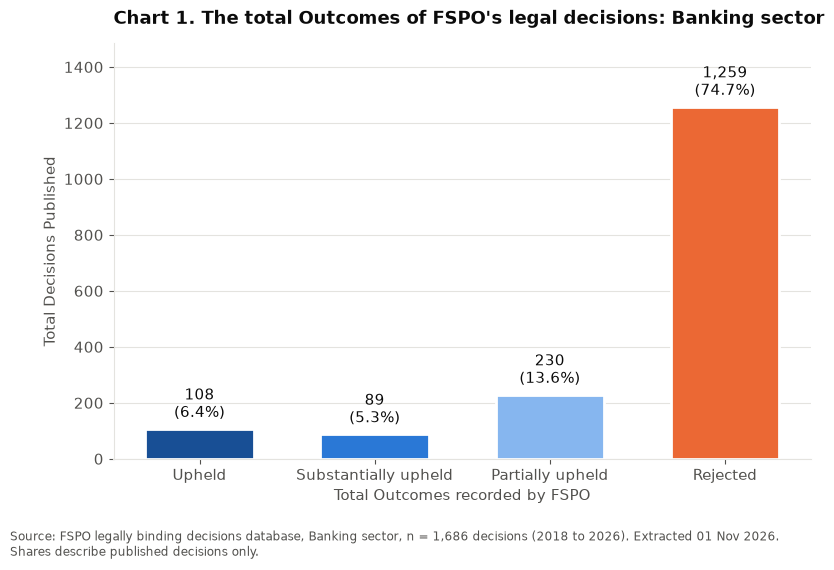

In [16]:
# Chart1: The outcome distribution
d = dist.drop("Total")
fig, ax = plt.subplots(figsize=(9, 5.4))
bars = ax.bar(d.index, d["count"], width=0.62, color=[OUTCOME_COLOURS[o] for o in d.index],
              edgecolor="white", linewidth=2)
for bar, (_, row) in zip(bars, d.iterrows()):
    ax.annotate(f"{int(row['count']):,}\n({row['percent']:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center", va="bottom")
ax.set_ylim(0, d["count"].max() * 1.18)
ax.set_ylabel("Total Decisions Published")
ax.set_xlabel("Total Outcomes recorded by FSPO")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.set_title("Chart 1. The total Outcomes of FSPO's legal decisions: Banking sector", loc="left", pad=14)
footer(fig, "Shares describe published decisions only.")
fig.savefig(CHART_DIR / "chart1_outcome_distribution.png")
plt.show()

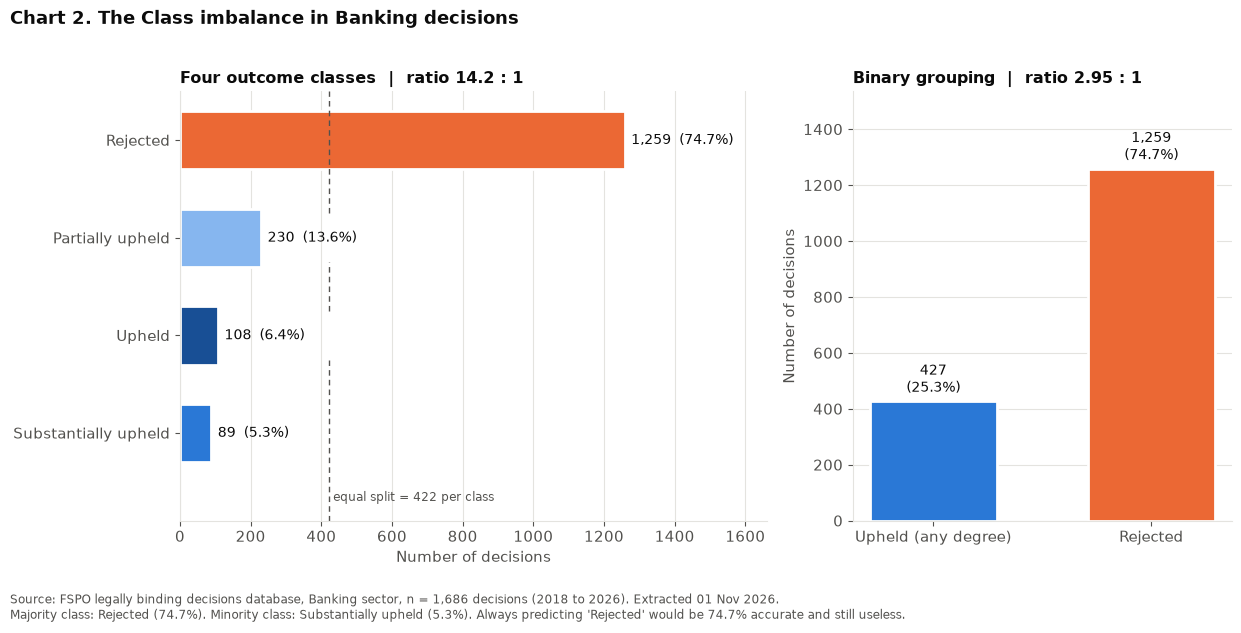

In [17]:
# Chart2:  The class imbalance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.6), gridspec_kw={"width_ratios": [1.55, 1]})

order = d.sort_values("count")
ax1.barh(order.index, order["count"], height=0.6, color=[OUTCOME_COLOURS[o] for o in order.index],
         edgecolor="white", linewidth=2)
for y, (_, row) in enumerate(order.iterrows()):
    ax1.text(row["count"] + 18, y, f"{int(row['count']):,}  ({row['percent']:.1f}%)", va="center", fontsize=10)
balanced = imb_four["n"] / len(order)

label_width = order["count"].max() * 0.26
blocked = [y for y, c in enumerate(order["count"]) if c < balanced < c + label_width]

edges = [-0.9] + [e for y in blocked for e in (y - 0.25, y + 0.25)] + [len(order) - 0.5]
for y0, y1 in zip(edges[::2], edges[1::2]):
    
    ax1.plot([balanced, balanced], [y0, y1], color=INK_2, linestyle=(0, (4, 3)), linewidth=1)
    
ax1.text(balanced + 12, -0.66, f"equal split = {balanced:,.0f} per class", fontsize=8.5, color=INK_2, va="center")
ax1.set_xlim(0, order["count"].max() * 1.32)
ax1.set_ylim(-0.9, len(order) - 0.5)
ax1.set_xlabel("Number of decisions")
ax1.xaxis.grid(True, color=GRID)
ax1.set_axisbelow(True)
ax1.set_title(f"Four outcome classes  |  ratio {imb_four['imbalance_ratio']:.1f} : 1", loc="left", fontsize=11.5)

ax2.bar(binary_counts.index, binary_counts.values, width=0.58,
        color=[BINARY_COLOURS[k] for k in binary_counts.index], edgecolor="white", linewidth=2)

for x, v in enumerate(binary_counts.values):
    
    ax2.text(x, v + 18, f"{v:,}\n({v / binary_counts.sum() * 100:.1f}%)", ha="center", va="bottom", fontsize=10)
ax2.set_ylim(0, binary_counts.max() * 1.22)
ax2.set_ylabel("Number of decisions")
ax2.yaxis.grid(True, color=GRID)
ax2.set_axisbelow(True)
ax2.set_title(f"Binary grouping  |  ratio {imb_binary['imbalance_ratio']:.2f} : 1", loc="left", fontsize=11.5)

fig.suptitle("Chart 2. The Class imbalance in Banking decisions",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.02)
footer(fig, f"Majority class: {imb_four['majority_class']} ({imb_four['majority_share_pct']:.1f}%). "
            f"Minority class: {imb_four['minority_class']} ({imb_four['minority_share_pct']:.1f}%). "
            f"Always predicting '{imb_four['majority_class']}' would be "
            f"{imb_four['always_predict_majority_accuracy_pct']:.1f}% accurate and still useless.")
fig.tight_layout()
fig.savefig(CHART_DIR / "chart2_class_imbalance.png")
plt.show()

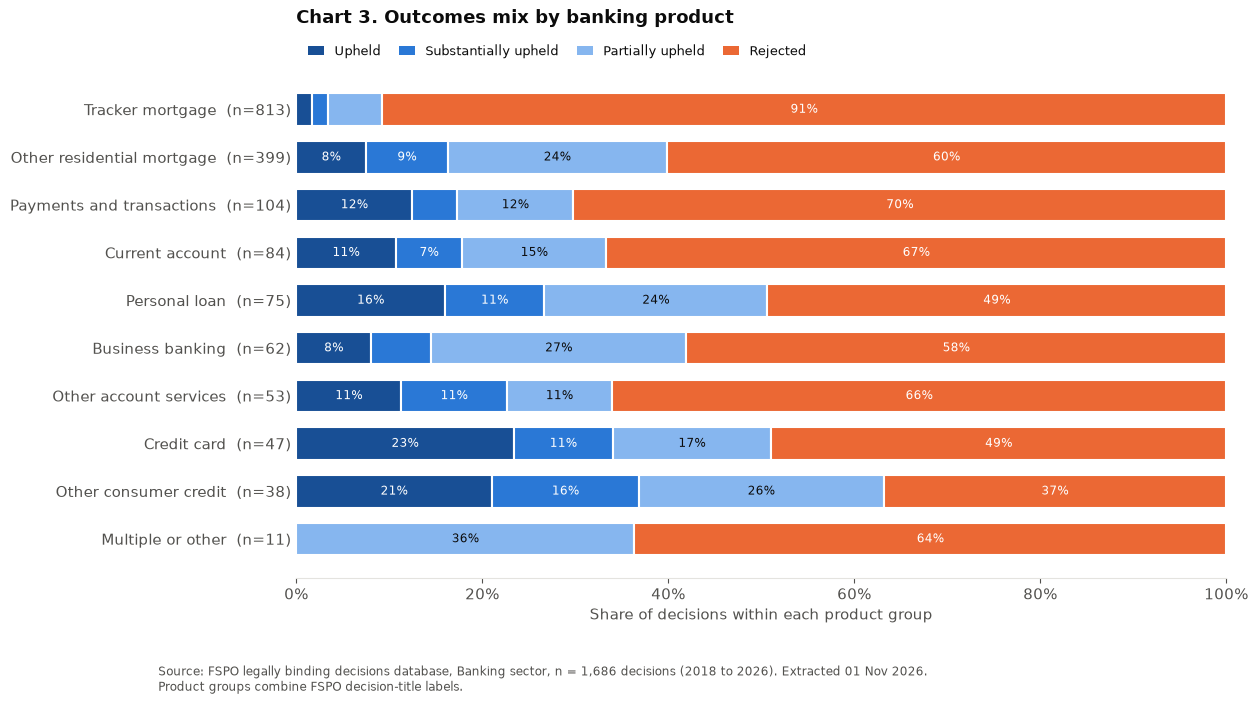

In [18]:
# Chart3 : outcomes by product group 
n = prod_counts.sum(axis=1)
order = n.sort_values().index
fig, ax = plt.subplots(figsize=(12, 6.6))
left = np.zeros(len(order))
for outcome in OUTCOME_ORDER:
    vals = prod_shares.loc[order, outcome].values
    ax.barh(range(len(order)), vals, left=left, height=0.68, color=OUTCOME_COLOURS[outcome],
            edgecolor="white", linewidth=1.5)
    for i, (v, l) in enumerate(zip(vals, left)):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.8,
                    color=INK if outcome == "Partially upheld" else "white")
    left += vals
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{g}  (n={n[g]:,})" for g in order])
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{t}%" for t in range(0, 101, 20)])
ax.set_xlabel("Share of decisions within each product group")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(facecolor=OUTCOME_COLOURS[o], label=o) for o in OUTCOME_ORDER], ncol=4,
          loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9.5, handlelength=1.2, columnspacing=1.4)
ax.set_title("Chart 3. Outcomes mix by banking product", loc="left", pad=34)
footer(fig, "Product groups combine FSPO decision-title labels.")
fig.savefig(CHART_DIR / "chart3_outcomes_by_product.png")
plt.show()

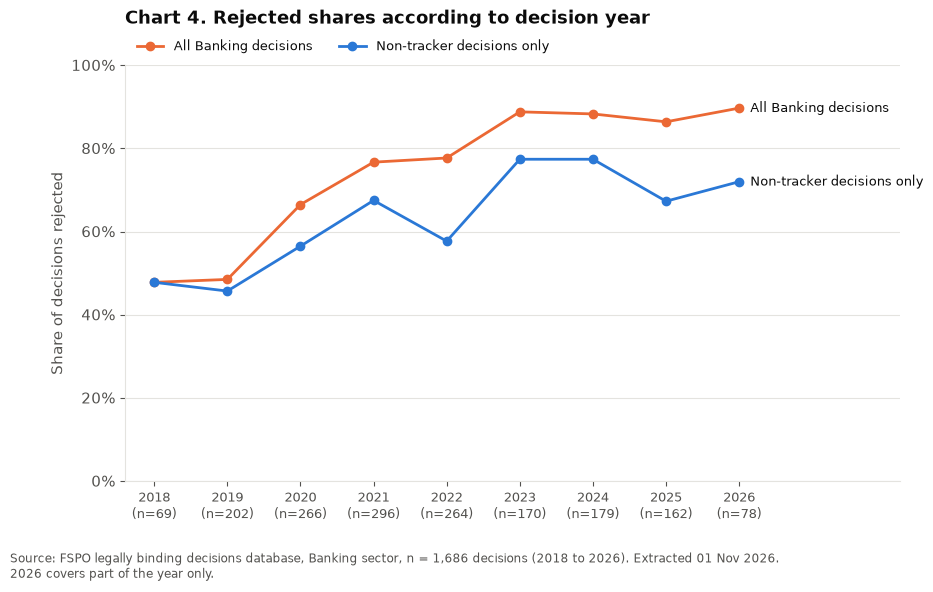

In [19]:
# Chart4: rejected share by year
yt = year_table.copy()
fig, ax = plt.subplots(figsize=(10, 5.4))

series = [("rejected_pct_all", "All Banking decisions", "#eb6834"),
          ("rejected_pct_non_tracker", "Non-tracker decisions only", "#2a78d6")]

for col, label, colour in series:
    
    ax.plot(yt.index, yt[col], color=colour, linewidth=2, marker="o", markersize=6, label=label)
    ax.annotate(label, (yt.index[-1], yt[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9.5, color=INK)
    
ax.set_ylim(0, 100)

ax.set_yticks(range(0, 101, 20))

ax.set_yticklabels([f"{t}%" for t in range(0, 101, 20)])

ax.set_xticks(yt.index)
ax.set_xticklabels([f"{y}\n(n={yt.loc[y, 'decisions']})" for y in yt.index], fontsize=9)
ax.set_xlim(yt.index.min() - 0.4, yt.index.max() + 2.2)
ax.set_ylabel("Share of decisions rejected")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9.5)
ax.set_title("Chart 4. Rejected shares according to decision year", loc="left", pad=30)
footer(fig, f"{latest_year} covers part of the year only.")
fig.savefig(CHART_DIR / "chart4_rejected_share_by_year.png")
plt.show()

##  Stats saved

In [20]:
stats = {
    "n_decisions": int(len(df)),
    "years": [int(df["decision_year"].min()), latest_year],
    "extracted_utc": verification["scraped_at_utc"],
    "site_note": verification["last_updated_note"],
    "matches_site_total": verification["matches_reported_total"],
    "filter_checks_matched": f"{sum(c['match'] for c in checks)} of {len(checks)}" if checks else "skipped",
    "outcome_distribution": {o: {"count": int(dist.loc[o, "count"]), "percent": float(dist.loc[o, "percent"])}
                             for o in OUTCOME_ORDER},
    "upheld_any_degree": {"count": upheld_any, "percent": round(upheld_any / len(df) * 100, 2)},
    "imbalance_four_class": imb_four,
    "imbalance_binary": imb_binary,
    "by_product_group": prod_table.reset_index().rename(columns={"product_group": "group"})
                                  .astype({c: "int64" for c in OUTCOME_ORDER + ["n"]}).to_dict("records"),
    "mortgage_decisions": morgage_num,
    "tracker": {"n": int(df["is_tracker_mortgage"].sum()),
                "rejected_pct": float(tracker.loc["Tracker mortgage", "Rejected %"])},
    "non_tracker": {"n": int((~df["is_tracker_mortgage"]).sum()),
                    "rejected_pct": float(tracker.loc["All other Banking", "Rejected %"])},
    "cbi_examination_conduct": cbi_exam,
    "by_year": {int(y): {k: float(v) for k, v in row.items()} for y, row in year_table.iterrows()},
    "primary_conduct": conduct.reset_index().to_dict("records"),
    "data_quality": {k: v for k, v in quality.items() if k not in ("missing_values_raw",)},
}
STATS_JSON.write_text(json.dumps(stats, indent=2, default=str), encoding="utf-8")
print("Saved", STATS_JSON)
for p in sorted(CHART_DIR.glob("*.png")):
    print("Chart:", p.name)

Saved C:\Users\Aditya\eda_statistics.json
Chart: chart1_outcome_distribution.png
Chart: chart2_class_imbalance.png
Chart: chart3_outcomes_by_product.png
Chart: chart4_rejected_share_by_year.png


## summary of the findings

In [21]:
t, o = stats["tracker"], stats["non_tracker"]
big = prod_table[prod_table["n"] >= 40].sort_values("Upheld any degree %", ascending=False)
FirsT_year, last_full = year_table.index.min(), year_table.index.max() - 1
print(f"1. Complete extract: {len(df):,} of {verification['reported_total']:,} decisions; "
      f"site filter checks matched: {stats['filter_checks_matched']}.")
print(f"2. Rejected {dist.loc['Rejected', 'percent']:.1f}% | Partially upheld {dist.loc['Partially upheld', 'percent']:.1f}% | "
      f"Upheld {dist.loc['Upheld', 'percent']:.1f}% | Substantially upheld {dist.loc['Substantially upheld', 'percent']:.1f}%. "
      f"Upheld to any degree: {stats['upheld_any_degree']['percent']:.1f}%.")
print(f"3. Imbalance: {imb_four['imbalance_ratio']:.2f}:1 (four classes), {imb_binary['imbalance_ratio']:.2f}:1 (binary). "
      f"Always guessing 'Rejected' scores {imb_four['always_predict_majority_accuracy_pct']:.1f}% accuracy.")
print(f"4. Mortgages are {morgage_num / len(df) * 100:.1f}% of decisions. Trackers: {t['n']:,} decisions, "
      f"{t['rejected_pct']:.1f}% rejected; everything else: {o['n']:,} decisions, {o['rejected_pct']:.1f}% rejected.")
print(f"5. Among groups with 40+ decisions, highest upheld-to-any-degree shares: " +
      "; ".join(f"{g} {r['Upheld any degree %']:.1f}% (n={int(r['n'])})" for g, r in big.head(2).iterrows()) + ".")
print(f"6. Rejected share: {year_table.loc[FirsT_year, 'rejected_pct_all']:.1f}% in {FirsT_year} vs "
      f"{year_table.loc[last_full, 'rejected_pct_all']:.1f}% in {last_full}; non-tracker only: "
      f"{year_table.loc[FirsT_year, 'rejected_pct_non_tracker']:.1f}% vs {year_table.loc[last_full, 'rejected_pct_non_tracker']:.1f}%.")
print("7. These are shares of published decisions, not the chance that a complaint succeeds.")

1. Complete extract: 1,686 of 1,686 decisions; site filter checks matched: 20 of 20.
2. Rejected 74.7% | Partially upheld 13.6% | Upheld 6.4% | Substantially upheld 5.3%. Upheld to any degree: 25.3%.
3. Imbalance: 14.15:1 (four classes), 2.95:1 (binary). Always guessing 'Rejected' scores 74.7% accuracy.
4. Mortgages are 71.9% of decisions. Trackers: 813 decisions, 90.8% rejected; everything else: 873 decisions, 59.7% rejected.
5. Among groups with 40+ decisions, highest upheld-to-any-degree shares: Credit card 51.1% (n=47); Personal loan 50.7% (n=75).
6. Rejected share: 47.8% in 2018 vs 86.4% in 2025; non-tracker only: 47.8% vs 67.3%.
7. These are shares of published decisions, not the chance that a complaint succeeds.
